# Analisis exploratorio de datos
### Librerías y unión de bases limpias

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Rutas a los archivos generados en la Etapa 2
carpeta_actual = Path.cwd()
raiz = carpeta_actual if (carpeta_actual / "listings.csv").is_file() else carpeta_actual.parent
carpeta_datos = raiz / "Ingenieria de Datos" / "datos_procesados"

limpios = pd.read_csv(carpeta_datos / "anuncios_limpios.csv",
                      dtype={"id": "string", "host_id": "string"})
codificados = pd.read_csv(carpeta_datos / "anuncios_con_precio_codificados.csv",
                          dtype={"id": "string", "host_id": "string"})

# Unimos el precio por noche a la tabla limpia para el EDA
df = limpios.merge(codificados[["id", "precio_noche_usd"]], on="id", how="left", validate="one_to_one")
df_precio = df.dropna(subset=["precio_noche_usd"]).copy()

# La partición por anfitrión se fijó en la etapa 2.
assert df["grupo_anfitrion"].isin(["referencia", "reserva"]).all()
assert df.groupby("host_id")["grupo_anfitrion"].nunique().eq(1).all()
df_referencia = df.loc[df["grupo_anfitrion"].eq("referencia")].copy()
precio_referencia = df_referencia.dropna(subset=["precio_noche_usd"]).copy()

print(f"Total anuncios: {len(df):,} | Con precio publicado: {len(df_precio):,}")
print(f"Referencia: {len(df_referencia):,} anuncios, {len(precio_referencia):,} con precio. "
      f"Reserva con precio: {len(df_precio) - len(precio_referencia):,}.")
display(df_precio.head())

Total anuncios: 13,253 | Con precio publicado: 11,614
Referencia: 10,410 anuncios, 9,137 con precio. Reserva con precio: 2,477.


,id,host_id,barrio,tipo_habitacion,tipo_propiedad,banos,privacidad_bano,servicios_declarados,declara_wifi,declara_cocina,...,dias_disponibles_365,n_resenas,habitaciones,camas,noches_minimas,habitaciones_imputado,camas_imputado,banos_imputado,noches_minimas_imputado,precio_noche_usd
0,6,29,north hills,entire home/apt,entire home,2.0,sin_especificar,79,1,1,...,248,266,3,6,2,0,0,0,0,316.00
1,12447,48669,pacific beach,private room,private room in condo,1.0,privado,27,1,1,...,342,14,1,1,6,0,1,0,0,146.50
2,62274,302986,pacific beach,private room,private room in home,1.0,privado,34,1,0,...,193,1047,1,1,1,0,0,0,0,121.00
4,723387,3736562,pacific beach,entire home/apt,entire cottage,1.0,sin_especificar,52,1,1,...,309,202,1,1,1,0,0,0,0,282.00
5,741131,1291828,linda vista,entire home/apt,entire loft,1.0,sin_especificar,37,1,1,...,337,59,1,1,31,0,0,0,0,104.98


### Descripción del mercado de San Diego
Usamos todos los anuncios para resumir el mercado. Los precios se describen sobre los anuncios con tarifa publicada y las calificaciones sobre los anuncios calificados.

In [2]:
num_cols = [
    "precio_noche_usd", "capacidad", "habitaciones", "camas", "banos",
    "servicios_declarados", "noches_minimas", "dias_disponibles_365", "n_resenas"
]

resumen = df_precio[num_cols].describe().T
resumen["asimetria"] = df_precio[num_cols].skew()
resumen["curtosis"] = df_precio[num_cols].kurt()
display(resumen[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "asimetria", "curtosis"]].round(2))

# Calificación únicamente sobre anuncios que sí tienen calificación
calif_validas = df.loc[df["tiene_calificacion"] == 1, "calificacion"]
print("Resumen de calificaciones (anuncios calificados):")
display(calif_validas.describe().to_frame().T.round(2))

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
precio_noche_usd,11614.0,379.52,402.91,18.78,162.34,270.38,463.67,9863.0,6.75,99.34
capacidad,11614.0,5.27,3.43,1.00,2.00,4.00,7.00,16.0,1.23,1.27
habitaciones,11614.0,1.99,1.44,0.00,1.00,2.00,3.00,32.0,2.21,20.47
camas,11614.0,2.93,2.41,1.00,1.00,2.00,4.00,37.0,3.48,26.43
banos,11614.0,1.68,1.05,0.00,1.00,1.00,2.00,23.0,3.06,25.58
servicios_declarados,11614.0,45.92,16.99,0.00,34.00,47.00,58.00,110.0,-0.18,-0.33
noches_minimas,11614.0,9.88,16.14,1.00,2.00,2.00,30.00,365.0,6.68,113.84
dias_disponibles_365,11614.0,235.25,109.17,0.00,150.00,264.00,332.00,365.0,-0.59,-0.94
n_resenas,11614.0,79.08,124.73,0.00,3.00,30.00,101.00,1918.0,3.39,20.12


Resumen de calificaciones (anuncios calificados):


,count,mean,std,min,25%,50%,75%,max
calificacion,11099.0,4.81,0.33,1.0,4.77,4.9,4.98,5.0


Esta tabla resume el comportamiento numérico de los 11.614 anuncios con precio publicado y los 11.099 con calificación, evidenciando la presencia de valores extremos y asimetrías

### Distribuciones univariadas: Histogramas con subplots
Visualizamos la distribución del precio (en escala original y logarítmica), la capacidad y las calificaciones.

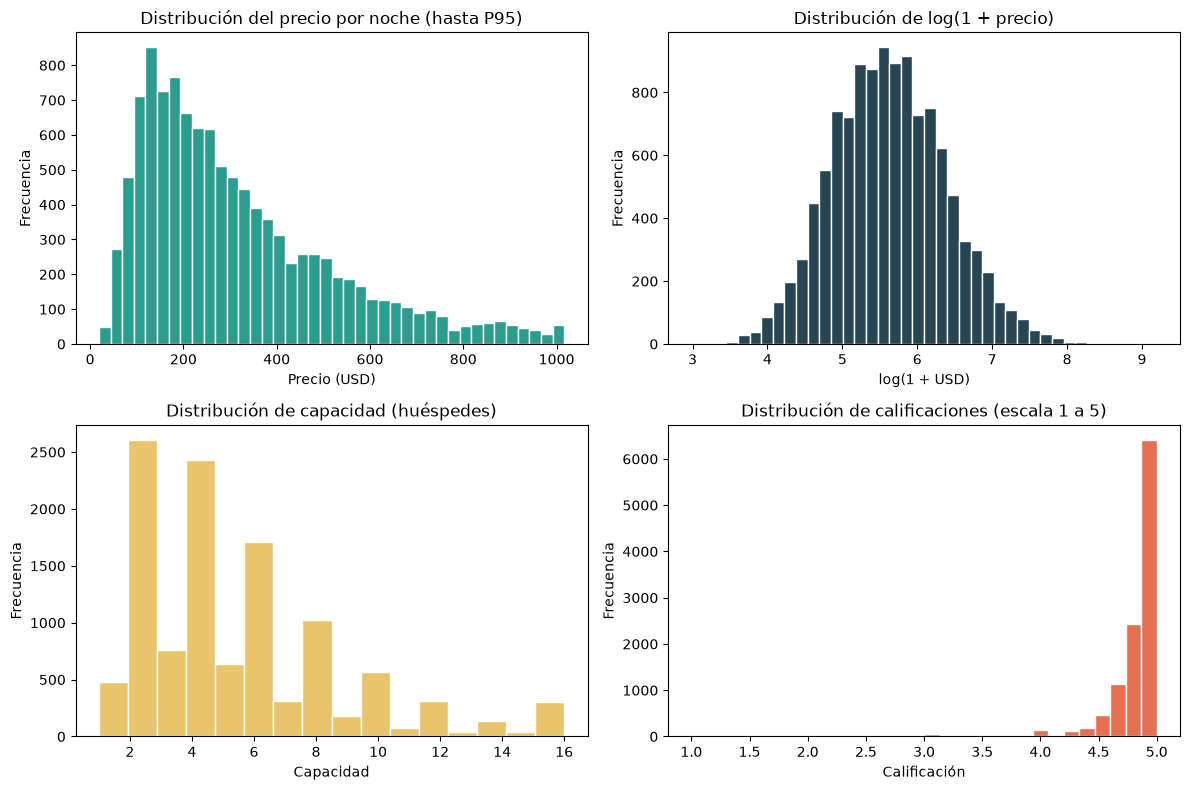

Mercado completo · mediana publicada (USD):


superanfitrion
0    224.34
1    302.95
Name: precio_noche_usd, dtype: float64

Diferencia entre las medianas de los dos grupos: 35.0 %


In [3]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# 1. Precio recortado al percentil 95 para ver la forma principal
p95 = df_precio["precio_noche_usd"].quantile(0.95)
ax[0, 0].hist(df_precio.loc[df_precio["precio_noche_usd"] <= p95, "precio_noche_usd"],
              bins=40, color="#2a9d8f", edgecolor="white")
ax[0, 0].set_title("Distribución del precio por noche (hasta P95)")
ax[0, 0].set_xlabel("Precio (USD)")
ax[0, 0].set_ylabel("Frecuencia")

# 2. Logaritmo del precio (útil para el modelo de regresión)
ax[0, 1].hist(np.log1p(df_precio["precio_noche_usd"]), bins=40, color="#264653", edgecolor="white")
ax[0, 1].set_title("Distribución de log(1 + precio)")
ax[0, 1].set_xlabel("log(1 + USD)")
ax[0, 1].set_ylabel("Frecuencia")

# 3. Capacidad de huéspedes
ax[1, 0].hist(df_precio["capacidad"], bins=16, color="#e9c46a", edgecolor="white")
ax[1, 0].set_title("Distribución de capacidad (huéspedes)")
ax[1, 0].set_xlabel("Capacidad")
ax[1, 0].set_ylabel("Frecuencia")

# 4. Calificaciones (solo anuncios con calificación)
ax[1, 1].hist(calif_validas, bins=30, color="#e76f51", edgecolor="white")
ax[1, 1].set_title("Distribución de calificaciones (escala 1 a 5)")
ax[1, 1].set_xlabel("Calificación")
ax[1, 1].set_ylabel("Frecuencia")

fig.tight_layout()
plt.show()

medianas_mercado = df_precio.groupby("superanfitrion")["precio_noche_usd"].median()
print("Mercado completo · mediana publicada (USD):")
display(medianas_mercado.round(2))
print(f"Diferencia entre las medianas de los dos grupos: "
      f"{100 * (medianas_mercado.loc[1] / medianas_mercado.loc[0] - 1):.1f} %")

Los cuatro histogramas confirman visualmente las propiedades estadísticas vistas en las celdas anteriores. En el mercado completo también comparamos las medianas de las tarifas publicadas según el estatus del anfitrión.

### Análisis bivariado en el grupo de referencia
A partir de aquí usamos los anuncios de referencia para explorar variables de modelado. Comparamos los precios por tipo de habitación y por estatus de superanfitrión. El grupo de reserva queda para la evaluación final.

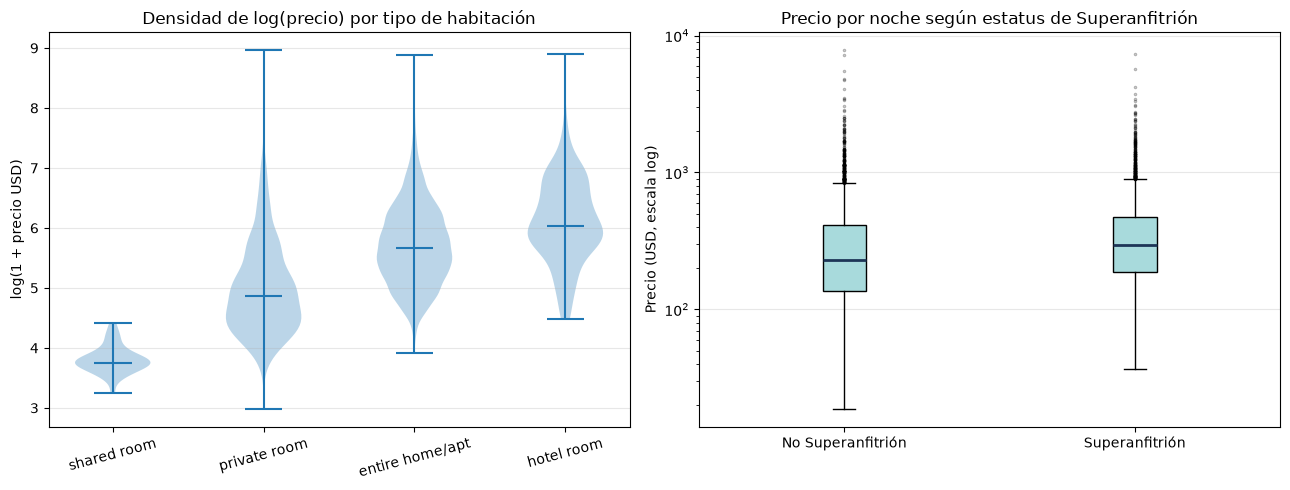

,count,median,mean
tipo_habitacion,,,
entire home/apt,7603,290.00,388.90
hotel room,218,415.45,582.45
private room,1282,129.12,208.13
shared room,34,41.60,45.15


,anuncios,mediana_precio,mediana_resenas
superanfitrion,,,
0,3988,227.67,7.0
1,5149,296.00,57.0


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 1. Diagrama de violín: log(precio) por tipo de habitación
orden_tipos = precio_referencia.groupby("tipo_habitacion")["precio_noche_usd"].median().sort_values().index
grupos_tipo = [np.log1p(precio_referencia.loc[precio_referencia["tipo_habitacion"] == t, "precio_noche_usd"])
               for t in orden_tipos]

ax[0].violinplot(grupos_tipo, showmedians=True)
ax[0].set_xticks(range(1, len(orden_tipos) + 1), labels=orden_tipos, rotation=15)
ax[0].set_title("Densidad de log(precio) por tipo de habitación")
ax[0].set_ylabel("log(1 + precio USD)")
ax[0].grid(axis="y", alpha=0.3)

# 2. Diagrama de caja: precio (escala log) según superanfitrión
grupos_super = [
    precio_referencia.loc[precio_referencia["superanfitrion"] == 0, "precio_noche_usd"],
    precio_referencia.loc[precio_referencia["superanfitrion"] == 1, "precio_noche_usd"]
]
ax[1].boxplot(grupos_super, tick_labels=["No Superanfitrión", "Superanfitrión"], patch_artist=True,
              boxprops={"facecolor": "#a8dadc"}, medianprops={"color": "#1d3557", "linewidth": 2},
              flierprops={"marker": ".", "markersize": 3, "alpha": 0.3})
ax[1].set_yscale("log")
ax[1].set_title("Precio por noche según estatus de Superanfitrión")
ax[1].set_ylabel("Precio (USD, escala log)")
ax[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

# Tabla resumen por tipo de habitación y superanfitrión
display(precio_referencia.groupby("tipo_habitacion")["precio_noche_usd"].agg(["count", "median", "mean"]).round(2))
display(precio_referencia.groupby("superanfitrion").agg(
    anuncios=("id", "size"),
    mediana_precio=("precio_noche_usd", "median"),
    mediana_resenas=("n_resenas", "median")
).round(2))

En el grupo de referencia, la mediana de la tarifa publicada es mayor entre superanfitriones. Barrio, capacidad y tipo de alojamiento también pueden diferir entre los grupos. Para estimar cuánto cambiaría la tarifa de un mismo anuncio al obtener el estatus haría falta una comparación que tuviera en cuenta esas diferencias.

### Análisis geográfico y de barrios: Dispersión espacial y Top barrios
Usamos ax.scatter con mapa de colores (cmap) para ver cómo se distribuyen los precios geográficamente en San Diego.

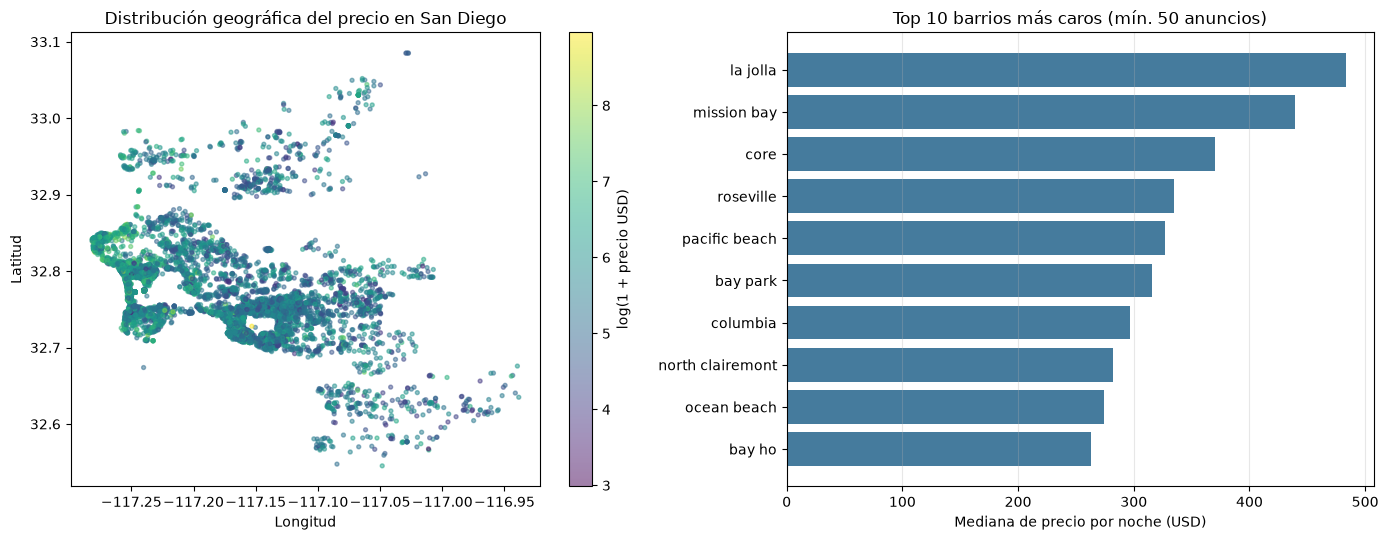

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Mapa de dispersión geográfica coloreado por log(precio)
sc = ax[0].scatter(precio_referencia["longitud"], precio_referencia["latitud"],
                   c=np.log1p(precio_referencia["precio_noche_usd"]),
                   cmap="viridis", s=8, alpha=0.5)
fig.colorbar(sc, ax=ax[0], label="log(1 + precio USD)")
ax[0].set_title("Distribución geográfica del precio en San Diego")
ax[0].set_xlabel("Longitud")
ax[0].set_ylabel("Latitud")

# 2. Top 10 barrios más caros (con al menos 50 anuncios para evitar sesgo por muestras pequeñas)
barrios = precio_referencia.groupby("barrio")["precio_noche_usd"].agg(["count", "median"])
top10_caros = barrios[barrios["count"] >= 50].sort_values("median", ascending=True).tail(10)

ax[1].barh(top10_caros.index, top10_caros["median"], color="#457b9d")
ax[1].set_title("Top 10 barrios más caros (mín. 50 anuncios)")
ax[1].set_xlabel("Mediana de precio por noche (USD)")
ax[1].grid(axis="x", alpha=0.3)

fig.tight_layout()
plt.show()

En el grupo de referencia se observan tarifas altas cerca de la costa. La comparación por barrio usa la mediana y exige al menos 50 anuncios con precio.

### Selección de predictores en el grupo de referencia
Calculamos las correlaciones y examinamos la relación entre capacidad y precio solo entre los anuncios de referencia con tarifa publicada.

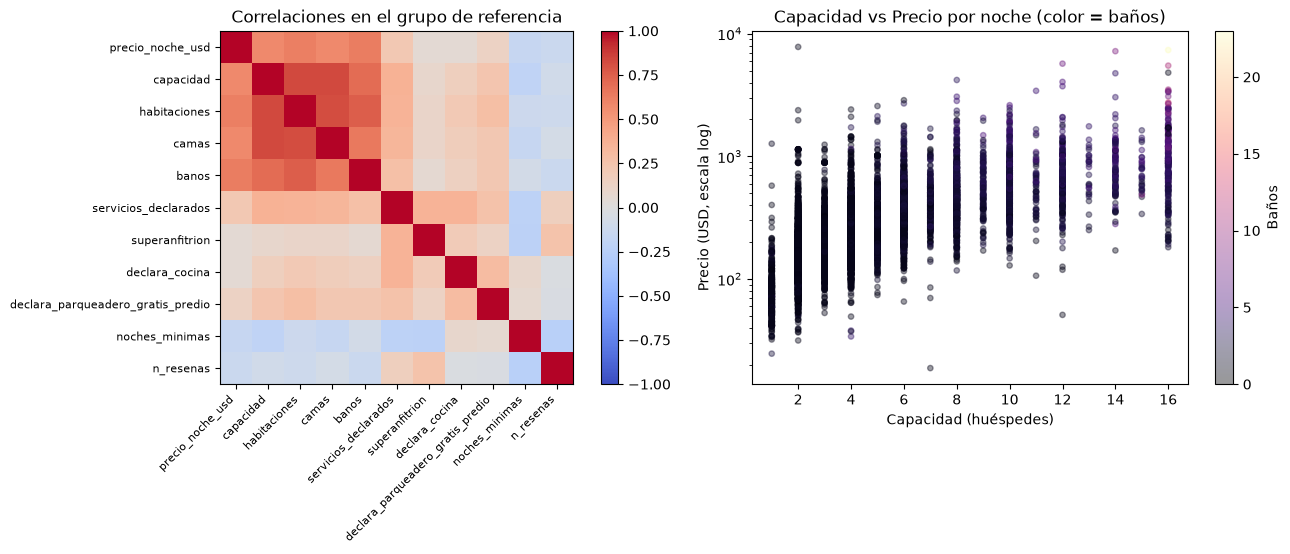

,Correlación con precio
precio_noche_usd,1.000
banos,0.633
habitaciones,0.620
capacidad,0.577
camas,0.575
servicios_declarados,0.213
declara_parqueadero_gratis_predio,0.127
declara_cocina,0.054
superanfitrion,0.047
n_resenas,-0.126


Asimetría en referencia: precio = 5.76, log(1 + precio) = 0.21.


In [6]:
vars_corr = [
    "precio_noche_usd", "capacidad", "habitaciones", "camas", "banos",
    "servicios_declarados", "superanfitrion", "declara_cocina",
    "declara_parqueadero_gratis_predio", "noches_minimas", "n_resenas"
]
corr = precio_referencia[vars_corr].corr()

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Mapa de calor de correlaciones
im = ax[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(vars_corr)), labels=vars_corr, rotation=45, ha="right", fontsize=8)
ax[0].set_yticks(range(len(vars_corr)), labels=vars_corr, fontsize=8)
ax[0].set_title("Correlaciones en el grupo de referencia")
fig.colorbar(im, ax=ax[0])

# 2. Dispersión: Capacidad vs Precio (coloreado por número de baños)
sc2 = ax[1].scatter(precio_referencia["capacidad"], precio_referencia["precio_noche_usd"],
                    c=precio_referencia["banos"], cmap="magma", alpha=0.4, s=15)
ax[1].set_yscale("log")
ax[1].set_title("Capacidad vs Precio por noche (color = baños)")
ax[1].set_xlabel("Capacidad (huéspedes)")
ax[1].set_ylabel("Precio (USD, escala log)")
fig.colorbar(sc2, ax=ax[1], label="Baños")

fig.tight_layout()
plt.show()

display(corr["precio_noche_usd"].sort_values(ascending=False).to_frame("Correlación con precio").round(3))

tarifa_referencia = precio_referencia["precio_noche_usd"]
print(f"Asimetría en referencia: precio = {tarifa_referencia.skew():.2f}, "
      f"log(1 + precio) = {np.log1p(tarifa_referencia).skew():.2f}.")

Los baños, las habitaciones, la capacidad y las camas tienen las mayores correlaciones lineales con la tarifa en referencia. Su correlación mutua invita a comprobar si cada variable mejora la predicción. La transformación logarítmica reduce la asimetría observada en este grupo.

### Ingeniería de características y exploración para clasificación
Resumimos las estancias de referencia con precio. Para describir la etiqueta de recomendación usamos todos los anuncios de referencia, incluidos aquellos que carecen de tarifa publicada.

In [7]:
# Precio por huésped para descripción. Usarlo como predictor del precio revelaría la respuesta.
precio_referencia["precio_por_huesped"] = precio_referencia["precio_noche_usd"] / precio_referencia["capacidad"]
precio_referencia["camas_por_habitacion"] = precio_referencia["camas"] / precio_referencia["habitaciones"].replace(0, 1)

# Discretización de la estancia mínima (usando pd.cut como en los notebooks guía)
precio_referencia["tipo_estancia"] = pd.cut(
    precio_referencia["noches_minimas"],
    bins=[0, 2, 7, 29, np.inf],
    labels=["Corta (1-2)", "Semanal (3-7)", "Media (8-29)", "Larga (30+)"]
)
display(precio_referencia.groupby("tipo_estancia", observed=False)["precio_noche_usd"].agg(["count", "median", "mean"]).round(2))

# Propuesta de variable objetivo para clasificación: Recomendado
# Criterio: calificación publicada de al menos 4.8 y al menos 10 reseñas.
df_referencia["recomendado"] = (
    (df_referencia["tiene_calificacion"] == 1) &
    (df_referencia["calificacion"] >= 4.8) &
    (df_referencia["n_resenas"] >= 10)
).astype(int)

print("Distribución de anuncios recomendados en referencia (criterio base: calif >= 4.8 y >= 10 reseñas):")
display(df_referencia["recomendado"].value_counts(normalize=True).mul(100).round(2).to_frame("% de referencia"))

,count,median,mean
tipo_estancia,,,
Corta (1-2),5566,303.88,385.42
Semanal (3-7),1245,393.67,509.68
Media (8-29),50,215.04,246.07
Larga (30+),2276,145.03,246.06


Distribución de anuncios recomendados en referencia (criterio base: calif >= 4.8 y >= 10 reseñas):


,% de referencia
recomendado,
0,54.73
1,45.27
